# Analyse Officer_filings (cours 2,3 et 4)

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 30)
REF_DATE = pd.Timestamp("2025-12-31")

<b> Décision </b>: Date de référence. Les mandats encore en cours n’ont pas de date de fin. Pour mesurer leur durée, on les arrête au 31/12/2025, puisque les données les plus récentes datent de 2025.

## Exploration des données

#### Chargement et inventaire

In [4]:
offilings = pd.read_csv("officer_filings_cleaned.csv",
                        parse_dates=["appointment_date", "cessation_date", "filing_date"])
print(offilings.shape)

inventaire = pd.DataFrame({
    "type": offilings.dtypes.astype(str),
    "valeurs_distinctes": offilings.nunique(),
    "manquants": offilings.isna().sum(),
})
inventaire

(135, 12)


,type,valeurs_distinctes,manquants
filing_id,str,135,0
registration_number,str,24,0
officer_local_ref,str,104,0
full_name,str,104,0
birth_year_or_age_band,str,50,0
nationality_or_region,str,5,0
role_title,str,54,0
appointment_date,datetime64[us],52,0
cessation_date,datetime64[us],37,77
filing_date,datetime64[us],133,0


On a :
- 135 id différents pour les 135 lignes.
- 104 registration number et full_name, soient 104 personnes (officers) distincts. Certains peuvent apparaitre plusieurs fois avec un nouveau mandat, post différent ou dans une autre entreprise.
- registration_number à 24, donc on regarde les officiers de 24 entreprises.
- cessation_date a 77 manquants; on pose l'hypothèse que c'est des mandats tjr actifs.





#### Typage des variables

Identifiants :  
- filing_id (clé de la déclaration) 135
- registration_number (l’entreprise) 24
- officer_local_ref (la personne) 104

Nominales non ordonnées:
- nationality_or_region (5 modalités)
- service_address (12)
- filing_status (2)
- role_title (54 modalités pour 135 lignes, presque du texte libre)

Variable mixte:
- birth_year_or_age_band : c'est soit une année exacte comme 1923, soit une tranche comme 1923-1929. On va devoir les séparer en deux.

Dates: (elles seront transformées en durées et en années)
- appointment_date
- cessation_date
- filing_date

#### Construction des variables numériques

In [ ]:
# durée du mandat, en jours (vide si le mandat n'est pas terminé)
offilings["tenure_days"] = (offilings["cessation_date"] - offilings["appointment_date"]).dt.days
# temps mis à déclarer la nomination, en jours
offilings["filing_delay_days"] = (offilings["filing_date"] - offilings["appointment_date"]).dt.days
# année de nomination
offilings["appointment_year"] = offilings["appointment_date"].dt.year
# année de naissance : la colonne contient soit "1971", soit "1970–1979"
b = offilings["birth_year_or_age_band"]
offilings["birth_is_band"] = b.str.contains("[–-]", regex=True)
offilings["birth_year"] = pd.to_numeric(b.where(b.str.fullmatch(r"\d{4}")), errors="coerce")

# pour les tranches, on prend le milieu (1970–1979 -> 1974.5) afin de pouvoir calculer un âge
milieu_tranche = b.str.extract(r"(\d{4})\D+(\d{4})").astype(float).mean(axis=1)
offilings["birth_year_est"] = offilings["birth_year"].fillna(milieu_tranche)

# âge au moment de la nomination
offilings["age_at_appointment"] = offilings["appointment_year"] - offilings["birth_year_est"]

offilings[["full_name", "appointment_date", "cessation_date", "tenure_days", "filing_delay_days",
           "appointment_year", "birth_year_or_age_band", "birth_year", "birth_year_est", "age_at_appointment"]].head()

,full_name,appointment_date,cessation_date,tenure_days,filing_delay_days,appointment_year,birth_year_or_age_band,birth_year,birth_year_est,age_at_appointment
0,Edward Vann,1840-01-01,1888-12-31,17897.0,68,1840,1815,1815.0,1815.0,25.0
1,Emil Warden,1895-01-01,1943-12-31,17895.0,12,1895,1871,1871.0,1871.0,24.0
2,Adrian Vosmere,1952-01-01,1991-12-31,14609.0,15,1952,1920–1929,NaN,1924.5,27.5
3,Dr. Elias Voss,1996-01-01,NaT,NaN,45,1996,1961,1961.0,1961.0,35.0
4,J. Varlan,1885-01-01,1918-12-31,12416.0,72,1885,1862,1862.0,1862.0,23.0


#### Statistiques descriptives et distributions

In [6]:
num_cols = ["tenure_days", "filing_delay_days", "appointment_year", "birth_year", "age_at_appointment"]

def describe_numeric(df, cols):
    return pd.DataFrame({
        "n":          df[cols].count(),
        "manquants":  df[cols].isna().sum(),
        "moyenne":    df[cols].mean(),
        "écart-type": df[cols].std(),
        "min":        df[cols].min(),
        "Q1":         df[cols].quantile(.25),
        "médiane":    df[cols].median(),
        "Q3":         df[cols].quantile(.75),
        "max":        df[cols].max(),
        "skewness":   df[cols].skew(),
    }).round(2)

display(describe_numeric(offilings, num_cols))

for c in num_cols:
    x = offilings[c].dropna()
    print(f"{c:20s} p-value Shapiro = {stats.shapiro(x).pvalue:.4f}")

,n,manquants,moyenne,écart-type,min,Q1,médiane,Q3,max,skewness
tenure_days,58,77,4151.10,4388.25,-367.0,1460.0,3286.0,4290.75,17897.0,1.72
filing_delay_days,135,0,44.58,19.28,10.0,28.0,48.0,62.50,74.0,-0.22
appointment_year,135,0,1996.29,23.63,1840.0,1990.0,1999.0,2008.50,2026.0,-3.75
birth_year,101,34,1968.56,25.67,1815.0,1962.0,1973.0,1983.00,1994.0,-3.58
age_at_appointment,135,0,28.08,4.59,19.5,24.0,27.0,31.00,43.5,0.73


tenure_days          p-value Shapiro = 0.0000
filing_delay_days    p-value Shapiro = 0.0000
appointment_year     p-value Shapiro = 0.0000
birth_year           p-value Shapiro = 0.0000
age_at_appointment   p-value Shapiro = 0.0000


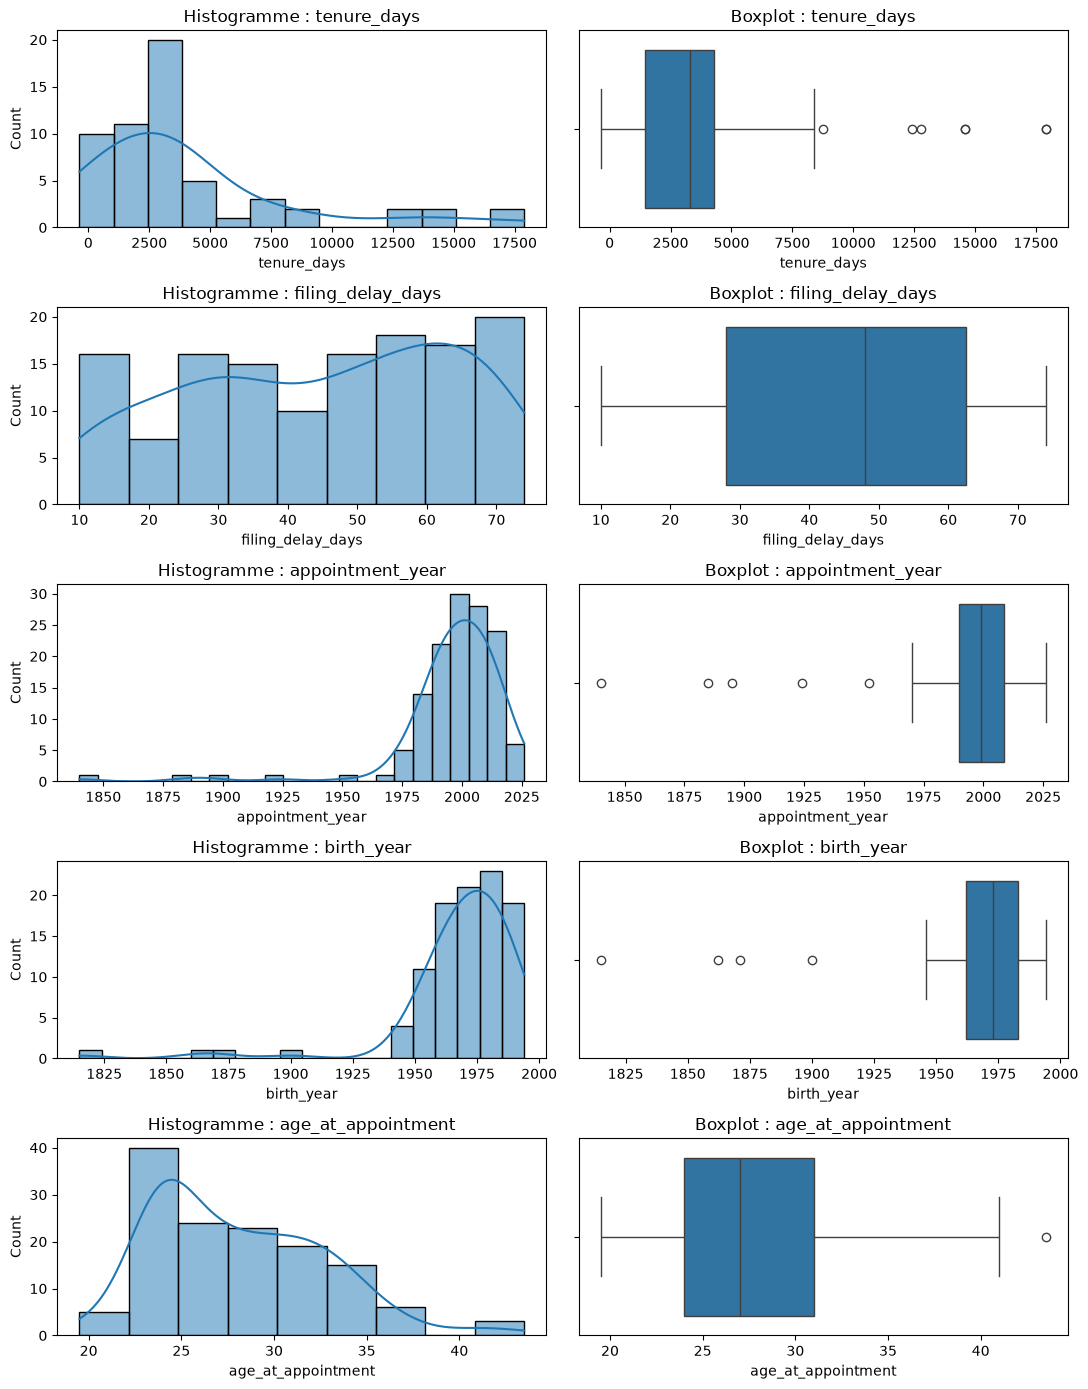

In [7]:
fig, ax = plt.subplots(len(num_cols), 2, figsize=(11, 2.8 * len(num_cols)))
for i, c in enumerate(num_cols):
    sns.histplot(offilings[c].dropna(), kde=True, ax=ax[i, 0])
    ax[i, 0].set_title(f"Histogramme : {c}")
    sns.boxplot(x=offilings[c].dropna(), ax=ax[i, 1])
    ax[i, 1].set_title(f"Boxplot : {c}")
plt.tight_layout()
plt.show()

Distributions:

Aucune variable ne suit une loi normale (Shapiro-Wilk, p < 0,05 pour toutes), ni une loi de puissance.

- filing_delay_days est répartie de façon uniforme entre 10 et 74 jours, sans valeur extrême. Cela évoque un tirage aléatoire plutôt qu’un comportement réel ; cette variable sera peu informative.
- appointment_year et birth_year sont fortement asymétriques vers la gauche (skewness ≈ −3,7) : la grande majorité des nominations a lieu après 1970, mais quelques déclarations remontent au XIXᵉ siècle (nomination la plus ancienne en 1840, naissance en 1815). Elles seront étudiées dans la partie anomalies.
- tenure_days montre des mandats très longs (jusqu’à 49 ans) et des durées négatives (jusqu’à −367 jours), ce qui est logiquement impossible -> pareil, on garde ça pour la partie anomalies.
- age_at_appointment (médiane ≈ 27 ans, max 43,5 ans) ne présente pas de valeur aberrante.
- La nomination la plus récente date de 2026, après la date de référence choisie.

#### Variables catégorielles

Combien de fois apparait chaque modalité?

##### comptages et barplots


filing_status — 2 modalités
filing_status
active        77
historical    58
Name: count, dtype: int64

nationality_or_region — 5 modalités
nationality_or_region
Valennan     62
Nordhaven    27
Aveloran     19
Tembaran     17
Kintaran     10
Name: count, dtype: int64

role_title — 54 modalités
role_title
Operations manager            10
Programme manager              9
Regional adviser               9
Field research coordinator     5
Deputy director                5
Regional logistics manager     4
Corporate adviser              4
Strategic adviser              4
Policy consultant              4
Senior field analyst           4
Name: count, dtype: int64


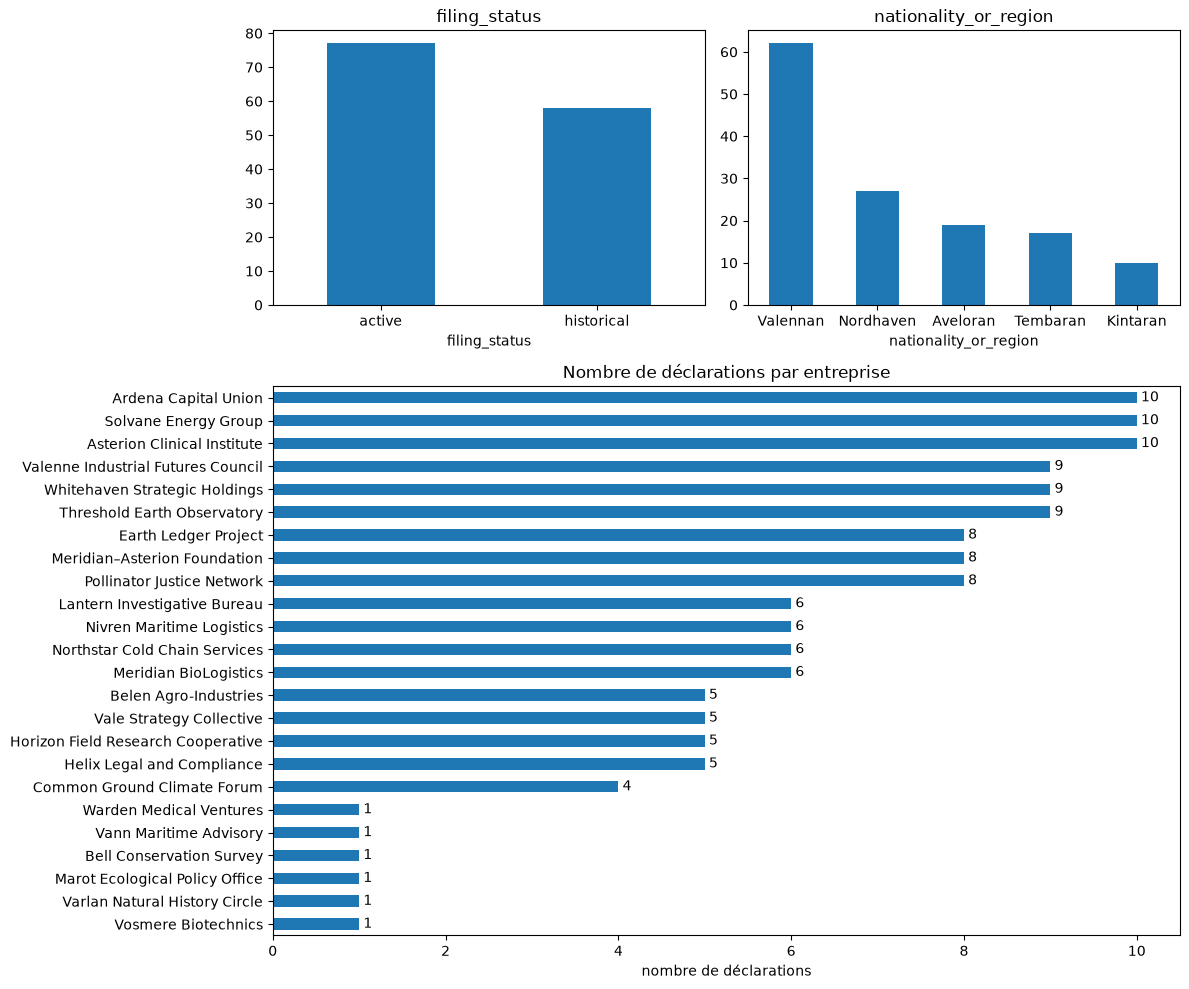

In [11]:
entities = pd.read_csv("registered_entities_cleaned.csv")
reg_name = dict(zip(entities["registration_number"], entities["legal_name"]))
offilings["entity"] = offilings["registration_number"].map(reg_name)

for c in ["filing_status", "nationality_or_region", "role_title"]:
    print(f"\n{c} — {offilings[c].nunique()} modalités")
    print(offilings[c].value_counts().head(10))

fig, ax = plt.subplot_mosaic([["statut", "nationalite"],
                              ["entreprises", "entreprises"]],
                             figsize=(12, 10), height_ratios=[1, 2])

offilings["filing_status"].value_counts().plot.bar(ax=ax["statut"], title="filing_status", rot=0)
offilings["nationality_or_region"].value_counts().plot.bar(ax=ax["nationalite"], title="nationality_or_region", rot=0)

counts = offilings["entity"].value_counts().sort_values()
counts.plot.barh(ax=ax["entreprises"], title="Nombre de déclarations par entreprise")
ax["entreprises"].bar_label(ax["entreprises"].containers[0], padding=3)
ax["entreprises"].set_ylabel("")
ax["entreprises"].set_xlabel("nombre de déclarations")

plt.tight_layout(); plt.show()

les cessations manquantes sont-elles des mandats en cours ?

In [12]:
pd.crosstab(offilings["filing_status"], offilings["cessation_date"].isna(),
            colnames=["cessation_date manquante"])

cessation_date manquante,False,True
filing_status,,
active,0,77
historical,58,0


Les 77 cessations vides sont exactement les 77 mandats actifs, et aucun mandat termminé n'a de date manquante. C'est un manque normal.

la domination valennane est elle normale?

In [13]:
print(entities["jurisdiction"].value_counts(normalize=True).round(2))
print()
print(offilings["nationality_or_region"].value_counts(normalize=True).round(2))

jurisdiction
Valenne Republic        0.50
Nordhaven Union         0.21
Avelora Federation      0.17
Kintara Republic        0.08
Tembara Commonwealth    0.04
Name: proportion, dtype: float64

nationality_or_region
Valennan     0.46
Nordhaven    0.20
Aveloran     0.14
Tembaran     0.13
Kintaran     0.07
Name: proportion, dtype: float64


50% des entreprises sont valennane et 46% des dirigeants le sont aussi, ce qui est assez proche. Cette domination vient donc du grand nombre d'entreprise compris à Valenne.

<b>Observations: </b>

- filing_status est équilibrée (77 déclarations actives, 58 historiques). Le tableau croisé montre que les 77 cessation_date manquantes correspondent exactement aux mandats actifs : il s’agit de mandats en cours, et non de données perdues. On ne les impute donc pas.
- nationality_or_region est dominée par les Valennans (46 %). Cette part est proche de celle des entreprises enregistrées en Valenne (50 %) : elle reflète la composition du registre et n’est pas suspecte.
- role_title compte 54 modalités pour 135 lignes, ce qui en fait presque du texte libre, peu exploitable par comptage. (compliqué et inutile à représenter en barplots)
- La plupart des entreprises ont entre 4 et 10 déclarations, mais 6 entreprises n’en ont qu’une seule (Vann Maritime Advisory, Warden Medical Ventures, Vosmere Biotechnics, Varlan Natural History Circle, Bell Conservation Survey, Marot Ecological Policy Office). Ce sont les entreprises liées aux nominations les plus anciennes, que l’on étudiera dans la partie anomalies.


#### corrélations

+1 : quand l’une monte, l’autre monte toujours

−1 : quand l’une monte, l’autre descend toujours

0 : aucun lien

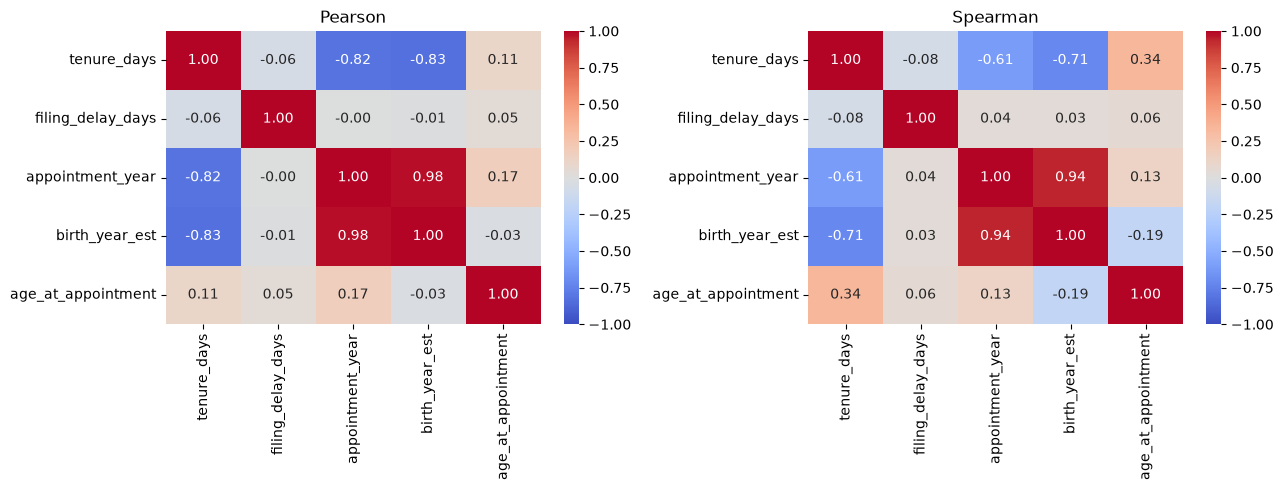

In [14]:
corr_cols = ["tenure_days", "filing_delay_days", "appointment_year", "birth_year_est", "age_at_appointment"]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, methode in zip(ax, ["pearson", "spearman"]):
    sns.heatmap(offilings[corr_cols].corr(method=methode), annot=True, fmt=".2f",
                cmap="coolwarm", vmin=-1, vmax=1, ax=a)
    a.set_title(methode.capitalize())
plt.tight_layout(); plt.show()

In [15]:
recent = offilings[offilings["appointment_year"] >= 1960]
print("Avec toutes les lignes :", round(offilings["tenure_days"].corr(offilings["appointment_year"]), 2))
print("Sans les nominations avant 1960 :", round(recent["tenure_days"].corr(recent["appointment_year"]), 2))

Avec toutes les lignes : -0.82
Sans les nominations avant 1960 : -0.49


<b>Corrélations</b> :
On compare Pearson (lien linéaire, sensible aux valeurs extrêmes) et Spearman (lien monotone, calculé sur les rangs, robuste).

- appointment_year et birth_year_est sont très fortement corrélées (0,98 / 0,94) : c’est mécanique, on est nommé quelques décennies après sa naissance.
- tenure_days est négativement corrélée à appointment_year (Pearson −0,82, Spearman −0,61) : les nominations anciennes ont eu des mandats plus longs. L’écart entre les deux coefficients vient de quelques mandats très anciens. Sans les nominations antérieures à 1960, Pearson tombe à −0,49.
- filing_delay_days n’est corrélée à aucune autre variable, ce qui confirme son caractère aléatoire.

Ces corrélations traduisent des relations de construction entre dates et non des liens de cause à effet. Il ne s'agit pas ici de découverte sur les dirigeants.


## Regroupement des déclarations